# Chapter 26: Incomplete, Relational, and Dynamic Contracts

This notebook reruns four worked examples from the chapter: debt priced around a costly audit, a self-enforcing bonus in a relational contract, reputation as collateral, and the hold-up of a specific investment. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def csv_debt(p_low, y_low, y_high, audit_cost, loan):
    """costly-state-verification: debt with audit in default. Lender break-even
    p_low (y_low - c) + (1 - p_low) D = loan.
    Book (ch026): 0.25(40 - 10) + 0.75 D = 80 gives D = 96.67, residual 140 - 96.67 = 43.33,
    expected audit 2.50, output 115, surplus 115 - 80 - 2.50 = 32.50; c = 50 gives D = 110."""
    recovery = y_low - audit_cost
    D = (loan - p_low * recovery) / (1 - p_low)
    residual = y_high - D
    exp_audit = p_low * audit_cost
    output = p_low * y_low + (1 - p_low) * y_high
    return {"D": D, "recovery_low": recovery, "residual_high": residual, "expected_audit": exp_audit,
            "output": output, "surplus": output - loan - exp_audit,
            "borrower_expected": (1 - p_low) * residual, "feasible": D <= y_high}


def relational_enforcement(temptation, per_period_gain, delta, bond=0.0):
    """relational-contracts and reputation-capital: a promise is self-enforcing when the one-time
    temptation is no larger than the discounted future loss delta / (1 - delta) x gain plus any
    separate bond or reputation asset B. Threshold delta* = (T - B) / (T - B + gain).
    Book (ch026): 0.8 / 0.2 x 40 = 160 >= 50; 0.2 / 0.8 x 40 = 10 < 50; repairer 0.75 / 0.25 x 20 = 60 >= 30,
    threshold 30 / (30 + 20) = 0.6, at 0.5 the rent 20 + B = 15 gives 35 > 30."""
    future = delta / (1 - delta) * per_period_gain
    loss = future + bond
    net_t = temptation - bond
    threshold = 0.0 if net_t <= 0 else (net_t / (net_t + per_period_gain) if per_period_gain > 0 else None)
    return {"future_loss": future, "total_loss": loss, "sustainable": loss >= temptation - 1e-9,
            "tie": abs(loss - temptation) < 1e-9, "threshold_delta": threshold}


def holdup_investment(base, invested, cost, share):
    """hold-up-problem: the investor keeps share s of the incremental quasi-rent after bargaining.
    Book (ch026): increment 100 - 40 = 60, joint net 60 - 35 = 25; at s = 0.5 the supplier gets
    50 - 20 = 30 < 35 and declines (private loss 5); at s = 0.7, 0.70(60) = 42 and it invests (gain 7)."""
    increment = invested - base
    private = share * increment
    gain = private - cost
    return {"increment": increment, "joint_net": increment - cost, "private_return": private,
            "private_gain": gain, "invests": gain >= 0, "tie": abs(gain) < 1e-9,
            "efficient": increment - cost > 0, "threshold_share": cost / increment}


plt.rcParams.update(HOUSE_RC)


information = SimpleNamespace(csv_debt=csv_debt, relational_enforcement=relational_enforcement, holdup_investment=holdup_investment)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'costly-state-verification': {'loan': 80,
                               'y_low': 40,
                               'p_low': 0.25,
                               'y_high': 140,
                               'audit_cost': 10,
                               'D_printed_as': 96.67,
                               'residual': 43.33,
                               'expected_audit': 2.5,
                               'audit_saving': 7.5,
                               'output': 115,
                               'surplus': 32.5,
                               'audit_cost_cf': 50,
                               'D_cf': 110,
                               'residual_cf': 30,
                               'expected_audit_cf': 12.5},
 'relational-contracts': {'effort_cost': 30,
                          'value_gain': 90,
                          'bonus': 50,
                          'delta': 0.8,
                          'supplier_gain': 20,
                          'manufacturer_gain': 40,
                          'future_loss': 160,
                          'honor_value': 200,
                          'surplus': 60,
                          'delta_cf': 0.2,
                          'future_loss_cf': 10},
 'reputation-capital': {'price': 90,
                        'honest_cost': 70,
                        'cheat_cost': 40,
                        'delta': 0.75,
                        'profit': 20,
                        'gain': 30,
                        'rent': 60,
                        'honesty_value': 80,
                        'cheat_value': 50,
                        'threshold': 0.6,
                        'delta_low': 0.5,
                        'rent_low': 20,
                        'B': 15,
                        'loss_with_B': 35},
 'hold-up-problem': {'base': 40,
                     'invested': 100,
                     'cost': 35,
                     'share': 0.5,
                     'increment': 60,
                     'joint_net': 25,
                     'private_return': 30,
                     'private_loss': 5,
                     'share_cf': 0.7,
                     'private_return_cf': 42,
                     'gain_cf': 7},
 'constructed': {'costly-state-verification': {'audit_cost': [0, 30], 'p_low': [0.15, 0.35]},
                 'relational-contracts': {'delta': [0.5, 0.9], 'bonus': [35, 70]},
                 'hold-up-problem': {'share': [0.6], 'cost': [25, 45]}}}


def csv_picture(c=10, pl=0.25):
    res = information.csv_debt(pl, 40, 140, c, 80)
    D, R = res["D"], res["recovery_low"]
    fig, ax = new_figure()
    stacked_bar(ax, ["Low state ($40)", "High state ($140)"],
                [[R, D], [c, 0], [0, res["residual_high"]]],
                ["lender keeps", "audit cost", "Maya keeps"], colors=["navy", "terracotta", "teal"],
                ylabel="Dollars", total_marker=False)
    hline(ax, 80, "loan $80", col="grey")
    ax.set_ylim(min(0, R) - 15, 165)
    if R < 0:  # the audit bar then rises above the $40 output; say why
        label(ax, -0.27, c, f"audit {num(c, 0)} > output 40", col="terracotta", ha="left", dx=0, dy=6)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Project outcome")
    pH = 1 - pl
    metrics = {"Face value D": money(D), "High-state residual": money(res["residual_high"]),
               "Expected audit cost": money(res["expected_audit"]), "Joint surplus": money(res["surplus"]),
               "Maya's expected residual": money(res["borrower_expected"])}
    prod = pl * R
    interp = (f"In the low state the lender recovers 40 - {num(c, 0)} = {num(R, 0)} after the audit. Break-even "
              f"needs D = (80 - {num(pl, 2)} x {signed(R, 0)}) / {num(pH, 2)} = {num(80 - prod)} / {num(pH, 2)} = "
              f"{money(D)}. Maya keeps 140 - {num(D)} = {num(res['residual_high'])} in the high state. Expected output "
              f"is {num(pl, 2)} x 40 + {num(pH, 2)} x 140 = {num(res['output'])}, so joint surplus is "
              f"{num(res['output'])} - 80 - {num(res['expected_audit'])} = {money(res['surplus'])}, all of it Maya's "
              f"because the lender only breaks even. "
              + ("With a free audit nothing is lost to verification." if c == 0 else
                 "The audit cost destroys value only in the low state."
                 + (f" Here the audit costs more than the {num(40, 0)} it recovers, so the result relies on the lender "
                    f"committing to audit anyway." if c > 40 else "")))
    steps = [f"Low-state recovery = 40 - {num(c, 0)} = {num(R, 0)}",
             f"D = (80 - {num(pl, 2)} x {signed(R, 0)}) / {num(pH, 2)} = {num(80 - prod)} / {num(pH, 2)} = {num(D)}",
             f"High-state residual = 140 - {num(D)} = {num(res['residual_high'])}",
             f"Expected audit cost = {num(pl, 2)} x {num(c, 0)} = {num(res['expected_audit'])}",
             f"Surplus = {num(res['output'])} - 80 - {num(res['expected_audit'])} = {num(res['surplus'])}"]
    alt = (f"Stacked bars for the low and high states with audit cost {num(c, 0)} and low-state probability "
           f"{num(pl, 2)}: face value {money(D)}, Maya keeps {money(res['residual_high'])} in the high state.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def relational_picture(delta=0.8, b=50):
    gain = 90 - b
    res = information.relational_enforcement(b, gain, delta)
    ok = res["sustainable"]
    ratio = delta / (1 - delta)
    fig, ax = new_figure()
    bar_compare(ax, ["Temptation to renege (bonus)", "Discounted future loss"], [b, res["future_loss"]],
                colors=["gold", "teal" if ok else "terracotta"],
                value_labels=[money(b), money(res["future_loss"])], ylabel="Dollars", xlabel="Manufacturer's comparison")
    ax.set_ylim(0, 820)
    label(ax, 0.5, 700, "bonus paid, supplier works hard" if ok else "bonus withheld, supplier shirks",
          col="teal" if ok else "terracotta", ha="center", dx=0, dy=0)
    outcome = "high effort, bonus paid" if ok else "low effort, no bonus"
    metrics = {"Supplier gain if paid": money(b - 30), "Manufacturer gain per quarter": money(gain),
               "Future loss from reneging": money(res["future_loss"]), "Temptation": money(b), "Outcome": outcome}
    cmp = ">=" if ok else "<"
    interp = (f"Paying the {money(b, 0)} bonus leaves the supplier {num(b, 0)} - 30 = {num(b - 30, 0)} and the "
              f"manufacturer 90 - {num(b, 0)} = {num(gain, 0)} per quarter. Reneging saves {num(b, 0)} now but loses "
              f"{num(delta, 2)} / (1 - {num(delta, 2)}) x {num(gain, 0)} = {num(ratio, 2)} x {num(gain, 0)} = "
              f"{num(res['future_loss'])}. Since {num(res['future_loss'])} {cmp} {num(b, 0)}, "
              + ("the promise is self-enforcing and the supplier exerts high effort." if ok else
                 "the manufacturer would renege, so the supplier anticipates it and exerts low effort."))
    steps = [f"Supplier gain = {num(b, 0)} - 30 = {num(b - 30, 0)}", f"Manufacturer gain = 90 - {num(b, 0)} = {num(gain, 0)}",
             f"Future loss = {num(ratio, 2)} x {num(gain, 0)} = {num(res['future_loss'])}",
             f"Compare {num(res['future_loss'])} {cmp} {num(b, 0)}: {outcome}"]
    alt = (f"Bars comparing the {money(b, 0)} temptation with the {money(res['future_loss'])} discounted future loss at "
           f"continuation factor {num(delta, 2)}: {outcome}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def reputation_picture(delta=0.75, bond=0):
    res = information.relational_enforcement(30, 20, delta, bond=bond)
    ds = np.linspace(0, 0.95, 300)
    fig, ax = new_figure()
    ax.plot(ds, ds / (1 - ds) * 20 + bond, color=PALETTE["teal"], linewidth=2.2,
            label=f"rent at risk with B = {num(bond, 0)}")
    hline(ax, 30, "cheating gain $30", col="terracotta", x_frac=0.02)
    vline(ax, res["threshold_delta"], f"threshold {num(res['threshold_delta'], 3)}", col="grey", y_frac=0.16)
    mark(ax, delta, res["total_loss"], f"{money(res['total_loss'])}", col="navy", dx=-8, ha="right")
    ax.set_xlim(0, 0.95)
    ax.set_ylim(0, 120)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Continuation factor delta")
    ax.set_ylabel("Dollars")
    ok, tie = res["sustainable"], res["tie"]
    verdict = ("the rent exactly equals the $30 gain: the weak inequality holds and honest quality is just sustained"
               if tie else "honest quality is sustained" if ok else "cheating pays")
    ratio = delta / (1 - delta)
    metrics = {"Honest profit per job": money(20), "Cheating gain": money(30),
               "Continuation rent": money(res["future_loss"]), "Total loss from cheating": money(res["total_loss"]),
               "Threshold delta": num(res["threshold_delta"], 3), "Outcome": "honest" if ok else "cheat"}
    interp = (f"Honest profit is 90 - 70 = 20 and cheating saves 70 - 40 = 30. The rent at risk is {num(delta, 2)} / "
              f"(1 - {num(delta, 2)}) x 20 = {num(res['future_loss'])}"
              + (f", plus the reputation asset {num(bond, 0)}, for {num(res['total_loss'])}" if bond else "")
              + f". So {verdict}. The threshold solves 30 - {num(bond, 0)} = delta / (1 - delta) x 20, so delta = "
              f"{num(30 - bond, 0)} / {num(50 - bond, 0)} = {num(res['threshold_delta'], 3)}.")
    steps = ["pi = 90 - 70 = 20", "G = 70 - 40 = 30",
             f"Rent = {num(ratio, 2)} x 20 = {num(res['future_loss'])}",
             f"Total loss = {num(res['future_loss'])} + {num(bond, 0)} = {num(res['total_loss'])}",
             f"Threshold = {num(30 - bond, 0)} / ({num(30 - bond, 0)} + 20) = {num(res['threshold_delta'], 3)}"]
    alt = (f"Rent at risk rising with the continuation factor, against the $30 cheating gain. At delta "
           f"{num(delta, 2)} with asset {num(bond, 0)} the loss is {money(res['total_loss'])}: {verdict}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def holdup_picture(s=0.5, k=35):
    res = information.holdup_investment(40, 100, k, s)
    ok = res["invests"]
    fig, ax = new_figure()
    bar_compare(ax, ["Supplier's return", "Investment cost", "Joint net surplus"],
                [res["private_return"], k, res["joint_net"]], colors=["teal" if ok else "terracotta", "gold", "navy"],
                value_labels=[f"${num(res['private_return'], 0)}m", f"${num(k, 0)}m", f"${num(res['joint_net'], 0)}m"],
                ylabel="Millions of dollars", xlabel="Supplier's decision")
    ax.set_ylim(0, 62)
    label(ax, 1, 55, "invests" if ok else "declines", col="teal" if ok else "terracotta", ha="center", dx=0, dy=0)
    decision = "invest" if ok else "decline"
    metrics = {"Incremental surplus": f"${num(res['increment'], 0)}m", "Joint net surplus": f"${num(res['joint_net'], 0)}m",
               "Supplier's incremental return": f"${num(res['private_return'], 0)}m", "Decision": decision,
               "Supplier's private gain": ("-" if res['private_gain'] < 0 else "") + f"${num(abs(res['private_gain']), 0)}m",
               "Threshold share": num(res["threshold_share"], 3)}
    cmp = ">" if ok else "<"
    interp = (f"Investing raises surplus by 100 - 40 = 60 at a cost of {num(k, 0)}, a joint gain of "
              f"60 - {num(k, 0)} = {num(res['joint_net'], 0)} million. The supplier keeps {num(s, 2)} x 60 = "
              f"{num(res['private_return'], 0)} million, which is {cmp} {num(k, 0)}, so it will {decision} "
              f"(private change {num(res['private_return'], 0)} - {num(k, 0)} = {num(res['private_gain'], 0)} million). "
              f"It needs a share of at least {num(k, 0)} / 60 = {num(res['threshold_share'], 3)}.")
    steps = ["Increment = 100 - 40 = 60", f"Joint net = 60 - {num(k, 0)} = {num(res['joint_net'], 0)}",
             f"Supplier return = {num(s, 2)} x 60 = {num(res['private_return'], 0)}",
             f"Private gain = {num(res['private_return'], 0)} - {num(k, 0)} = {num(res['private_gain'], 0)}: {decision}"]
    alt = (f"Bars for the supplier's return of {num(res['private_return'], 0)} million, the {num(k, 0)} million cost and "
           f"the {num(res['joint_net'], 0)} million joint net surplus at share {num(s, 2)}: the supplier will {decision}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Costly state verification: debt priced around an audit

Maya borrows \$80. The project returns \$40 with probability 0.25 and \$140 with probability 0.75. The low state defaults and is audited at cost $c$.

$$0.25(\$40-\$10)+0.75D=\$80, \qquad D=\frac{\$80-0.25(\$30)}{0.75}=\$96.67$$

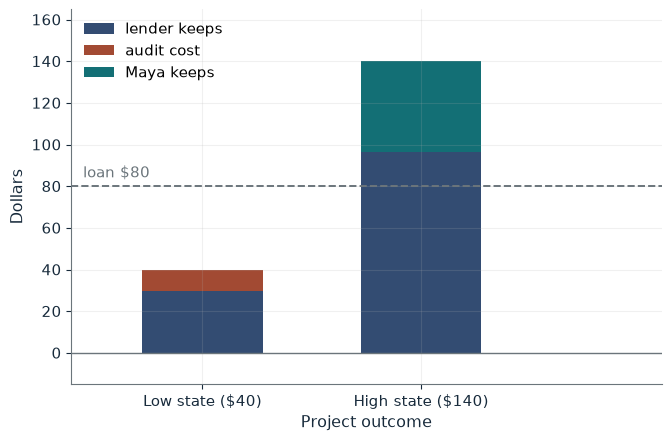

Face value D              $96.67
High-state residual       $43.33
Expected audit cost       $2.50
Joint surplus             $32.50
Maya's expected residual  $32.50

Worked steps:
  1. Low-state recovery = 40 - 10 = 30
  2. D = (80 - 0.25 x 30) / 0.75 = 72.50 / 0.75 = 96.67
  3. High-state residual = 140 - 96.67 = 43.33
  4. Expected audit cost = 0.25 x 10 = 2.50
  5. Surplus = 115.00 - 80 - 2.50 = 32.50

In the low state the lender recovers 40 - 10 = 30 after the audit. Break-even needs D = (80 - 0.25 x 30) / 0.75 = 72.50 / 0.75 = $96.67. Maya keeps 140 - 96.67 = 43.33 in the high state. Expected output is 0.25 x 40 + 0.75 x 140 = 115.00, so joint surplus is 115.00 - 80 - 2.50 = $32.50, all of it Maya's because the lender only breaks even. The audit cost destroys value only in the low state.


In [2]:
show(csv_picture(c=10, pl=0.25))

Change one input, `c`, and hold the others at the book's values:

In [3]:
sweep(csv_picture, 'c', [0, 10, 30, 50], {'pl': 0.25}, ['Face value D', 'High-state residual', 'Expected audit cost', 'Joint surplus'])

c | Face value D | High-state residual | Expected audit cost | Joint surplus
0 | $93.33 | $46.67 | $0.00 | $35.00
10 | $96.67 | $43.33 | $2.50 | $32.50
30 | $103.33 | $36.67 | $7.50 | $27.50
50 | $110.00 | $30.00 | $12.50 | $22.50


At an audit cost of \$10 the face value is \$96.67 and joint surplus \$32.50. At \$50 the face value rises to \$110, only \$13.33 more, because the audit happens in a quarter of outcomes.

## 2. Relational contracts: when is a handshake bonus self-enforcing?

High effort costs the supplier \$30 and is worth \$90 to the manufacturer, who promises a bonus $b$.

$$\frac{0.8}{1-0.8}\times\$40=\$160, \qquad \frac{0.2}{1-0.2}\times\$40=\$10$$

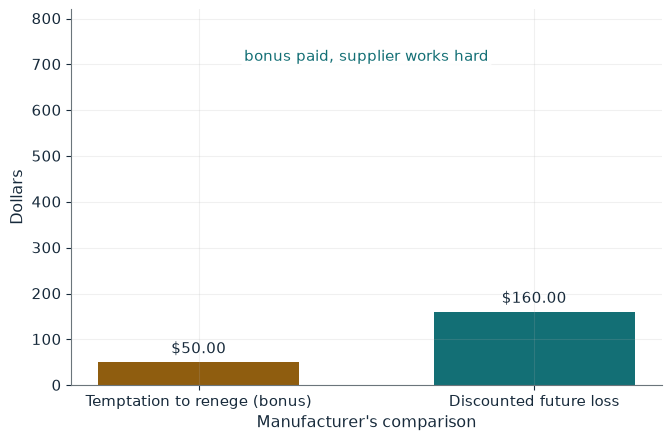

Supplier gain if paid          $20.00
Manufacturer gain per quarter  $40.00
Future loss from reneging      $160.00
Temptation                     $50.00
Outcome                        high effort, bonus paid

Worked steps:
  1. Supplier gain = 50 - 30 = 20
  2. Manufacturer gain = 90 - 50 = 40
  3. Future loss = 4.00 x 40 = 160.00
  4. Compare 160.00 >= 50: high effort, bonus paid

Paying the $50 bonus leaves the supplier 50 - 30 = 20 and the manufacturer 90 - 50 = 40 per quarter. Reneging saves 50 now but loses 0.80 / (1 - 0.80) x 40 = 4.00 x 40 = 160.00. Since 160.00 >= 50, the promise is self-enforcing and the supplier exerts high effort.


In [4]:
show(relational_picture(delta=0.8, b=50))

Change one input, `delta`, and hold the others at the book's values:

In [5]:
sweep(relational_picture, 'delta', [0.2, 0.5, 0.8, 0.9], {'b': 50}, ['Future loss from reneging', 'Outcome'])

delta | Future loss from reneging | Outcome
0.2 | $10.00 | low effort, no bonus
0.5 | $40.00 | low effort, no bonus
0.8 | $160.00 | high effort, bonus paid
0.9 | $360.00 | high effort, bonus paid


At delta 0.8 the \$160 future loss exceeds the \$50 temptation, so the bonus is paid and the supplier works hard. At 0.5 the loss is only \$40 and the promise collapses.

## 3. Reputation as contract-enforcement capital

Honest work earns \$90 - \$70 = \$20 per job; cheating saves \$70 - \$40 = \$30 once.

$$\frac{0.75}{1-0.75}\times\$20=\$60, \qquad \$30\leq\frac{\delta}{1-\delta}\times\$20$$

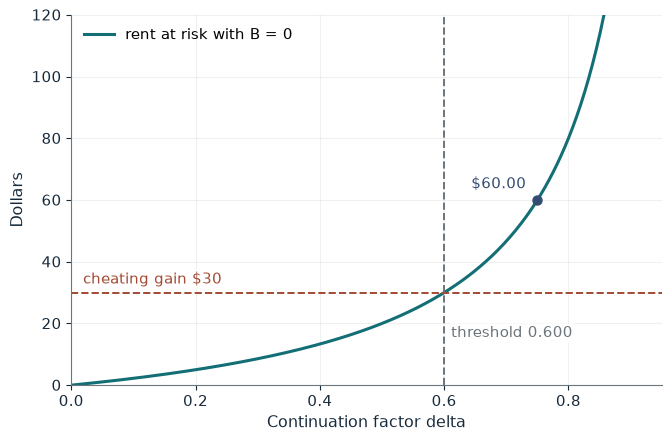

Honest profit per job     $20.00
Cheating gain             $30.00
Continuation rent         $60.00
Total loss from cheating  $60.00
Threshold delta           0.600
Outcome                   honest

Worked steps:
  1. pi = 90 - 70 = 20
  2. G = 70 - 40 = 30
  3. Rent = 3.00 x 20 = 60.00
  4. Total loss = 60.00 + 0 = 60.00
  5. Threshold = 30 / (30 + 20) = 0.600

Honest profit is 90 - 70 = 20 and cheating saves 70 - 40 = 30. The rent at risk is 0.75 / (1 - 0.75) x 20 = 60.00. So honest quality is sustained. The threshold solves 30 - 0 = delta / (1 - delta) x 20, so delta = 30 / 50 = 0.600.


In [6]:
show(reputation_picture(delta=0.75, bond=0))

Change one input, `delta`, and hold the others at the book's values:

In [7]:
sweep(reputation_picture, 'delta', [0.5, 0.6, 0.75], {'bond': 0}, ['Continuation rent', 'Outcome'])

delta | Continuation rent | Outcome
0.5 | $20.00 | cheat
0.6 | $30.00 | honest
0.75 | $60.00 | honest


Honesty holds for delta of at least 0.6; at exactly 0.6 the rent equals the \$30 gain. A separate \$15 asset lowers the threshold to 15 / 35 = 0.429.

## 4. Hold-up problem: the bargaining share

Surplus rises from \$40 million to \$100 million if the supplier sinks $k$ into a specialized line.

$$\$100-\$40=\$60\text{ million}, \qquad 0.70(\$60)=\$42\text{ million}$$

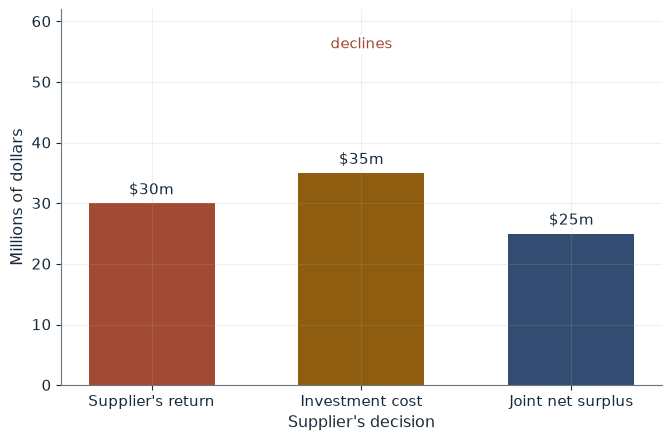

Incremental surplus            $60m
Joint net surplus              $25m
Supplier's incremental return  $30m
Decision                       decline
Supplier's private gain        -$5m
Threshold share                0.583

Worked steps:
  1. Increment = 100 - 40 = 60
  2. Joint net = 60 - 35 = 25
  3. Supplier return = 0.50 x 60 = 30
  4. Private gain = 30 - 35 = -5: decline

Investing raises surplus by 100 - 40 = 60 at a cost of 35, a joint gain of 60 - 35 = 25 million. The supplier keeps 0.50 x 60 = 30 million, which is < 35, so it will decline (private change 30 - 35 = -5 million). It needs a share of at least 35 / 60 = 0.583.


In [8]:
show(holdup_picture(s=0.5, k=35))

Change one input, `s`, and hold the others at the book's values:

In [9]:
sweep(holdup_picture, 's', [0.5, 0.6, 0.7], {'k': 35}, ["Supplier's incremental return", "Supplier's private gain", 'Decision'])

s | Supplier's incremental return | Supplier's private gain | Decision
0.5 | $30m | -$5m | decline
0.6 | $36m | $1m | invest
0.7 | $42m | $7m | invest


With half the increment the supplier gets \$30 million against a \$35 million cost and declines, although the joint gain is \$25 million. A share of 0.583 or more restores investment.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

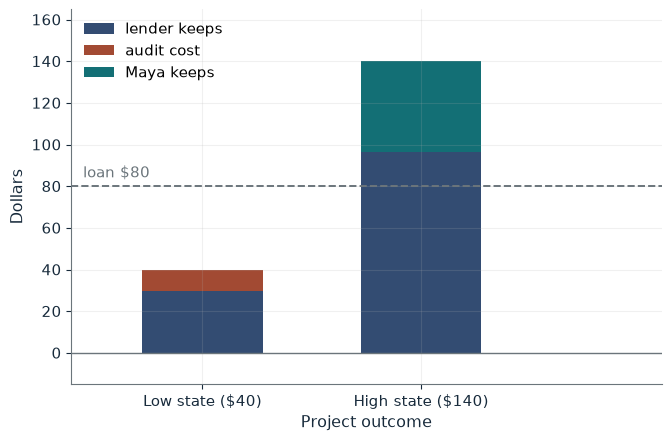

Face value D              $96.67
High-state residual       $43.33
Expected audit cost       $2.50
Joint surplus             $32.50
Maya's expected residual  $32.50

Worked steps:
  1. Low-state recovery = 40 - 10 = 30
  2. D = (80 - 0.25 x 30) / 0.75 = 72.50 / 0.75 = 96.67
  3. High-state residual = 140 - 96.67 = 43.33
  4. Expected audit cost = 0.25 x 10 = 2.50
  5. Surplus = 115.00 - 80 - 2.50 = 32.50

In the low state the lender recovers 40 - 10 = 30 after the audit. Break-even needs D = (80 - 0.25 x 30) / 0.75 = 72.50 / 0.75 = $96.67. Maya keeps 140 - 96.67 = 43.33 in the high state. Expected output is 0.25 x 40 + 0.75 x 140 = 115.00, so joint surplus is 115.00 - 80 - 2.50 = $32.50, all of it Maya's because the lender only breaks even. The audit cost destroys value only in the low state.


In [10]:
show(csv_picture(c=10, pl=0.25))

## Practice

**1.** At an audit cost of \$30 with a 0.25 chance of the low state, what face value lets the lender break even?

<details><summary>Answer</summary>

Recovery 40 - 30 = 10; D = (80 - 0.25 x 10) / 0.75 = 77.50 / 0.75 = \$103.33.

</details>

**2.** At delta = 0.5 and a \$70 bonus, is the bonus self-enforcing?

<details><summary>Answer</summary>

Future loss 1 x (90 - 70) = \$20 < \$70, so no: the manufacturer would renege and the supplier shirks.

</details>

**3.** At s = 0.60 and k = \$35 million, does the supplier invest?

<details><summary>Answer</summary>

0.60 x 60 = \$36 million > \$35 million, so yes, by \$1 million.

</details>